<a href="https://colab.research.google.com/github/manjunadha12/CSA4703-Deep-Learning/blob/main/Lab/Exp5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


Polynomial Degree: 1
Training MSE: 34711342181.48
Validation MSE: 32020583331.36

Polynomial Degree: 3
Training MSE: 25258732442.33
Validation MSE: 19527388330.24

Polynomial Degree: 9
Training MSE: 24645530324.86
Validation MSE: 22488618314.77

Polynomial Degree: 15
Training MSE: 25134491667.08
Validation MSE: 22025380463.72


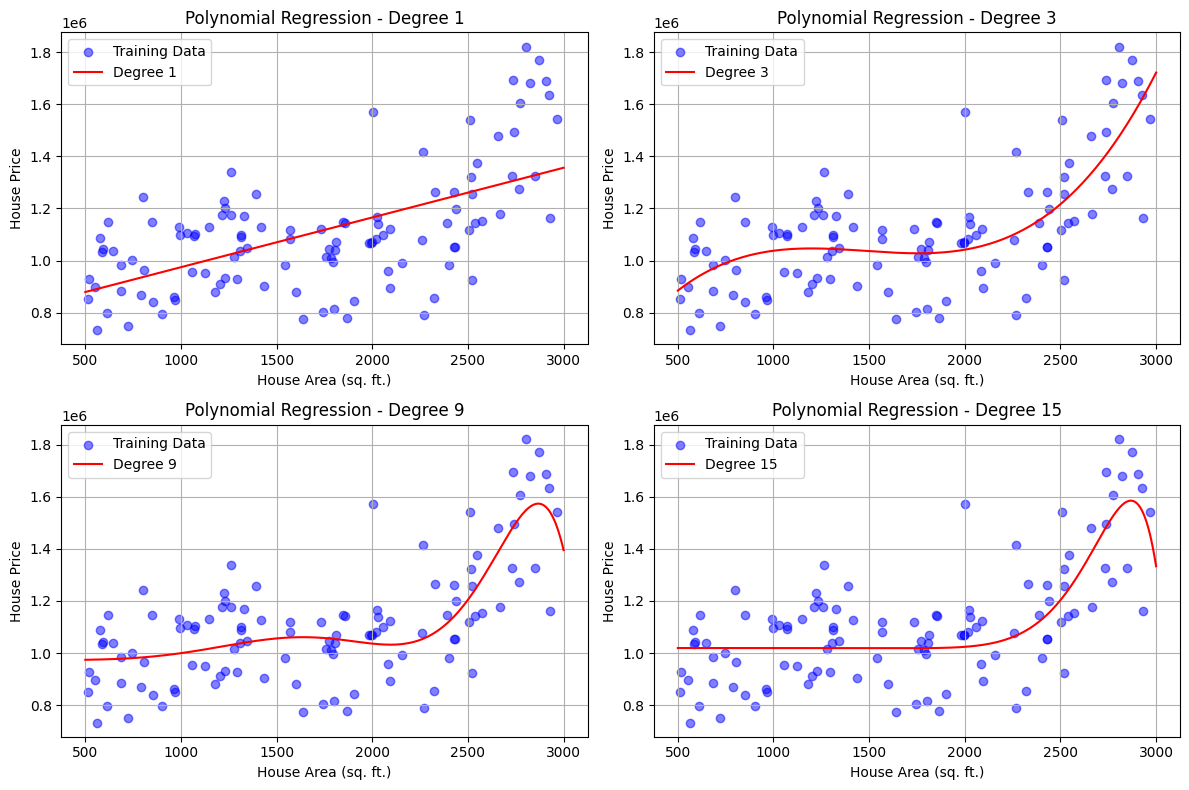

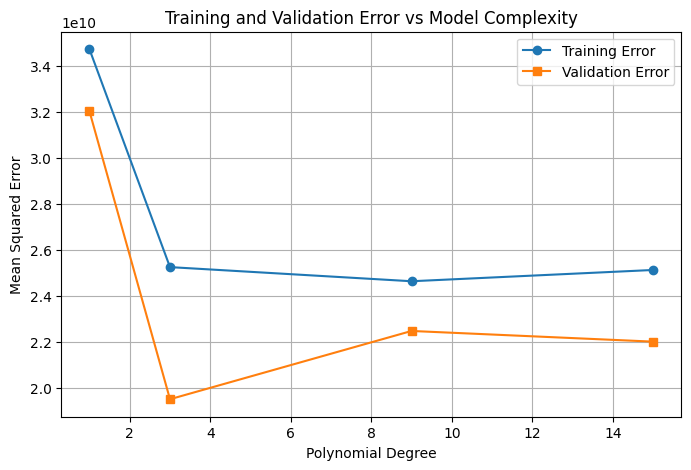


Degree: 1
Bias Squared: 16484963566.9
Variance: 772114175.51

Degree: 3
Bias Squared: 839393635.84
Variance: 1146719666.72

Degree: 9
Bias Squared: 3235983505.43
Variance: 1723099781.54

Degree: 15
Bias Squared: 4627170068.38
Variance: 2906431706.67


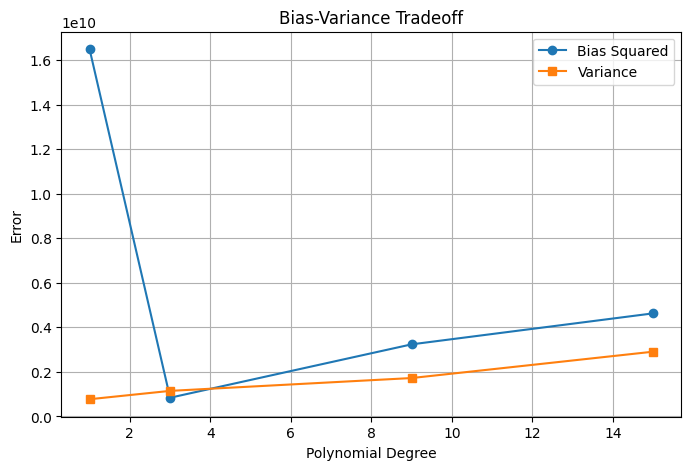


Best Polynomial Degree: 3
Lowest Validation MSE: 19527388330.24

House Area: 1800 sq. ft.
Predicted House Price: Rs. 1028552.39


In [1]:

import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

# 1. Generate 150 noisy house-area and price samples
np.random.seed(42)

X = np.sort(np.random.uniform(500, 3000, 150)).reshape(-1, 1)

# Hidden non-linear relationship
y = (
    500000
    + 200 * X.ravel()
    + 0.08 * (X.ravel() ** 2)
    + 300000 * np.sin(X.ravel() / 500)
    + np.random.normal(0, 150000, 150)
)

# Split into training and validation data
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.25, random_state=42
)

degrees = [1, 3, 9, 15]

train_errors = []
val_errors = []
models = {}

# 2. Fit polynomial regression models
plt.figure(figsize=(12, 8))

for i, degree in enumerate(degrees):
    model = make_pipeline(
        PolynomialFeatures(degree),
        LinearRegression()
    )

    model.fit(X_train, y_train)
    models[degree] = model

    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)

    train_mse = mean_squared_error(y_train, train_pred)
    val_mse = mean_squared_error(y_val, val_pred)

    train_errors.append(train_mse)
    val_errors.append(val_mse)

    print("\nPolynomial Degree:", degree)
    print("Training MSE:", round(train_mse, 2))
    print("Validation MSE:", round(val_mse, 2))

    # Plot fitted curve
    X_plot = np.linspace(500, 3000, 300).reshape(-1, 1)
    y_plot = model.predict(X_plot)

    plt.subplot(2, 2, i + 1)
    plt.scatter(X_train, y_train, color="blue",
                label="Training Data", alpha=0.5)
    plt.plot(X_plot, y_plot, color="red",
             label=f"Degree {degree}")
    plt.title(f"Polynomial Regression - Degree {degree}")
    plt.xlabel("House Area (sq. ft.)")
    plt.ylabel("House Price")
    plt.legend()
    plt.grid(True)

plt.tight_layout()
plt.show()

# 3. Plot training and validation errors
plt.figure(figsize=(8, 5))

plt.plot(degrees, train_errors, marker="o",
         label="Training Error")
plt.plot(degrees, val_errors, marker="s",
         label="Validation Error")

plt.xlabel("Polynomial Degree")
plt.ylabel("Mean Squared Error")
plt.title("Training and Validation Error vs Model Complexity")
plt.legend()
plt.grid(True)
plt.show()

# 4. Estimate bias squared and variance using repeated resampling
np.random.seed(42)

degrees = [1, 3, 9, 15]
X_test = np.linspace(500, 3000, 100).reshape(-1, 1)

# True relationship without noise
true_y = (
    500000
    + 200 * X_test.ravel()
    + 0.08 * (X_test.ravel() ** 2)
    + 300000 * np.sin(X_test.ravel() / 500)
)

bias_squared = []
variance_values = []

for degree in degrees:
    predictions = []

    # Train models on 50 different bootstrap samples
    for i in range(50):
        indices = np.random.choice(
            len(X_train), len(X_train), replace=True
        )

        X_sample = X_train[indices]
        y_sample = y_train[indices]

        model = make_pipeline(
            PolynomialFeatures(degree),
            LinearRegression()
        )

        model.fit(X_sample, y_sample)

        predictions.append(model.predict(X_test))

    predictions = np.array(predictions)

    average_prediction = np.mean(predictions, axis=0)

    # Bias squared
    bias = np.mean((average_prediction - true_y) ** 2)

    # Variance
    variance = np.mean(
        np.var(predictions, axis=0)
    )

    bias_squared.append(bias)
    variance_values.append(variance)

    print("\nDegree:", degree)
    print("Bias Squared:", round(bias, 2))
    print("Variance:", round(variance, 2))

# 5. Plot bias and variance
plt.figure(figsize=(8, 5))

plt.plot(degrees, bias_squared, marker="o",
         label="Bias Squared")
plt.plot(degrees, variance_values, marker="s",
         label="Variance")

plt.xlabel("Polynomial Degree")
plt.ylabel("Error")
plt.title("Bias-Variance Tradeoff")
plt.legend()
plt.grid(True)
plt.show()

# Select best model based on validation error
best_index = np.argmin(val_errors)
best_degree = [1, 3, 9, 15][best_index]

print("\nBest Polynomial Degree:", best_degree)
print("Lowest Validation MSE:", round(val_errors[best_index], 2))

# Display final prediction example
best_model = models[best_degree]
sample_area = np.array([[1800]])
predicted_price = best_model.predict(sample_area)

print("\nHouse Area:", sample_area[0][0], "sq. ft.")
print("Predicted House Price: Rs.", round(predicted_price[0], 2))
